In [ ]:
#@title Install dependencies [RUN ME]
!pip install --upgrade setuptools
!pip install ipykernel
!pip install pybind11
!pip install git+https://github.com/IAZero/wisardpkg.git@develop
!pip install numpy
!pip install matplotlib
!pip install scikit-learn
!pip install ipywidgets
!pip install numba
!git clone https://gist.github.com/1fe5c78be9a5ec2d507e8118e2c99740.git
!mv 1fe5c78be9a5ec2d507e8118e2c99740/*.py ./
!rm -rf ./1fe5c78be9a5ec2d507e8118e2c99740

  Cloning https://github.com/IAZero/wisardpkg.git (to revision develop) to /tmp/pip-req-build-baask4_2
  Running command git clone --filter=blob:none --quiet https://github.com/IAZero/wisardpkg.git /tmp/pip-req-build-baask4_2
  Running command git checkout -b develop --track origin/develop
  Switched to a new branch 'develop'
  Branch 'develop' set up to track remote branch 'develop' from 'origin'.
  Resolved https://github.com/IAZero/wisardpkg.git to commit c51b395c0e85ae007bb7f8699515a3136356ef65
  Preparing metadata (setup.py) ... done
  Created wheel for wisardpkg: filename=wisardpkg-2.0.0a7-cp312-cp312-linux_x86_64.whl size=5856618 sha256=0bb183c85c1f66ec7328b7a7dc75ce2428e1f04035a12584facd81434946ff25
  Stored in directory: /tmp/pip-ephem-wheel-cache-mm6f8una/wheels/50/3e/03/dd5396e10cc00163868ada49e05e6464110639bb276c6ecc7a
Successfully built wisardpkg
Cloning into '1fe5c78be9a5ec2d507e8118e2c99740'...
remote: Enumerating objects: 5, done.
remote: Total 5 (delta 0), reused 0 (de

In [ ]:
import wisardpkg as wp

import numpy as np

from ipywidgets import fixed, interact_manual

from IPython.display import display

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [6, 6]
plt.rcParams['figure.dpi'] = 80

from encoders import ThermometerEncoder, CircularThermometerEncoder, FloatBinaryEncoder, process_input, Morph, CodeWord, NeighborsSuffix, MockNeighborsSuffix
from datagen import linearly_separable_dataset, sinusoidal_dataset, radially_separable_dataset, sample_mental_image
from wisardviz import plot_decision_boundary, plot_imagined_points

In [ ]:
#@title Visualization helpers [RUN ME]

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.model_selection import train_test_split

import wisardpkg as wp

from encoders import process_input, Morph
from datagen import add_noise, sample_mental_image

def plot_decision_boundary(model, encoder, axis=None, x_range=[0.0, 1.0], y_range=[0.0, 1.0], step=0.005, title="Decision Boundary"):
    xmin, xmax = x_range
    ymin, ymax = y_range

    x, y = np.arange(xmin, xmax, step), np.arange(ymax, ymin, -step)
    X, Y = np.meshgrid(x, y)

    # predict = lambda x, y: int(model.classify(process_input([[x, y]], encoder))[0])
    predict = lambda x, y: int(
        model.classify(
            wp.DataSet(np.atleast_2d(
                process_input([[x, y]], encoder=encoder)).tolist())[0]))

    axis = plt.subplot() if axis is None else axis

    axis.set_title(title)
    return axis.contourf(X, Y, np.vectorize(predict)(X, Y))


def plot_imagined_points(model, encoder, kargs, axis=None, seed=None, alpha=0.5, title="Imagined Points"):
    mental_images = model.getMentalImages()

    # Normalize mental images
    for k in mental_images.keys():
        # TODO: This normalization may not be right!
        mental_images[k] = np.asarray(mental_images[k])/np.amax(mental_images[k])

    imagined_points = np.concatenate([
        encoder.decode(sample_mental_image(mental_images[k], kargs[k][1], seed=seed))
        for k in mental_images.keys()
    ])

    imagined_y = np.concatenate([
        np.repeat(k, kargs[k][1])
        for k in mental_images.keys()
    ]).astype(int)

    axis = plt.subplot() if axis is None else axis
    axis.set_title(title)
    axis.scatter(imagined_points[:, 0], imagined_points[:, 1], c=imagined_y, s=15, alpha=alpha)


def accuracy(y_pred, y_target):
    y_pred = np.asarray(y_pred)
    y_target = np.asarray(y_target)

    return np.where(y_pred == y_target, 1, 0).sum()/len(y_target)


def extrema(x):
    x = np.asarray(x)

    return (np.min(x), np.max(x))


def square_layout(nplots):
    nrows = 1
    ncols = 1

    while nplots > nrows*ncols:
        if nrows < ncols:
            nrows += 1
        else:
            ncols +=1

    return nrows, ncols


def classifier_testbed(X, y, tuple_size, noise, encoders, seed, bleaching=True, layout='square', subplot_size=(6, 6), mental_images=False):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=seed)

    # Add noise to training set
    y_train = add_noise(y_train, noise, seed)

    models = {k: wp.Wisard(tuple_size, bleachingActivated=bleaching) for k in encoders.keys()}

    # Train models and assess accuracy
    for k in encoders.keys():
        try:
            encoder_train, encoder_test = encoders[k]
        except TypeError:
            encoder_train = encoder_test = encoders[k]
        except ValueError:
            encoder_train = encoder_test = encoders[k][0]

        models[k].train(
#             encoder_train.encode(X_train),
            # process_input(X_train, encoder=encoders[k]),
            wp.DataSet(process_input(X_train, encoder=encoder_train),
            y_train.astype(str).tolist())
        )

        print(f"{k}:",
            accuracy(
                models[k].classify(
#                     encoder_test.encode(X_test),
                    # process_input(X_test, encoder=encoders[k])
                    wp.DataSet(process_input(X_test, encoder=encoder_test))
                ),
                y_test.astype(str)
            )
        )

    nplots = len(encoders)*(int(mental_images) + 1) + 1
    if layout == 'square':
        nrows, ncols = square_layout(nplots)
    elif layout == 'column':
        nrows = nplots
        ncols = 1
    else:
        nrows = 1
        ncols = nplots

    gs = GridSpec(nrows, ncols)
    fig = plt.figure(figsize=(subplot_size[0]*ncols, subplot_size[1]*nrows))

    plot_index = 0
    ax = fig.add_subplot(gs[plot_index])
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=10)
    ax.set_title('Training Data')
    x_lim = ax.get_xlim()
    y_lim = ax.get_ylim()
    x_range = extrema(X[:, 0])
    y_range = extrema(X[:, 1])
    plot_index += 1

    if mental_images:
        # Need to fix the encoding and morphing part
        for k in encoders.keys():
            try:
                encoder_train, encoder_test = encoders[k]
            except TypeError:
                encoder_train = encoder_test = encoders[k]
            except ValueError:
                encoder_train = encoder_test = encoders[k][0]

            ax = fig.add_subplot(gs[plot_index])
            ax.set_xlim(*x_lim)
            ax.set_ylim(*y_lim)
            plot_imagined_points(
                models[k],
                encoder_train, # Any encoder should do for decoding
                {
                    '1':  (sum(np.where(y_train == 1, 1, 0)), sum(np.where(y_train == 1, 1, 0))),
                    '-1': (sum(np.where(y_train == -1, 1, 0)), sum(np.where(y_train == -1, 1, 0)))
                },
                axis=ax,
                seed=seed,
                title=f"Mental image ({k})"
            )
            plot_index += 1

    for i, k in enumerate(encoders.keys()):
        try:
            encoder_train, encoder_test = encoders[k]
        except TypeError:
            encoder_train = encoder_test = encoders[k]
        except ValueError:
            encoder_train = encoder_test = encoders[k][0]

        ax = fig.add_subplot(gs[plot_index+i])
        ax.set_xlim(*x_lim)
        ax.set_ylim(*y_lim)
        plot_decision_boundary(
            models[k],
            encoder_test,
            ax,
            x_range,
            y_range,
            title=f"Decision boundary ({k})"
        )

# WiSARD for Real Values Inputs

## 1. Introduction

The WiSARD family of models is usually exemplified with classification tasks over images. However, the experience with other machine learning schemes have created the expectation that models be able to handle inputs in the form of real valued vectors. How can we achieve that if RAM discriminators expect to receive as input binary strings in order to address its constituent RAM neurons?

The obvious answer to this challenge seems to be that we need to convert our inputs of interest to binary strings, but how should we do that?

## 2. Encoding Schemes

### 2.1. Thermometer encoder

This binary enconder is suitable for situations where we can stablish a minimum and maximum for the variable we wish to discretize. We divide this range into $N$ intervals. The encoded output is a $N$-bit binary string, $S$, where $S_i$ represents the value of the $i$-th position, $i \in [0, N-1]$. If $V$ is the variable we wish to encode, $M$ is the maximum and $m$, the minimum, then

$$
S_i = \begin{cases}
  1 & \text{if} \quad V > m + i \times \frac{M - m}{N}\\
  0 & \text{otherwise}
\end{cases}
$$



Thermometer can handle real values:

In [ ]:
thermometer = ThermometerEncoder(minimum=0, maximum=1, resolution=10)

In [ ]:
thermometer.encode(0.16)

array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
thermometer.encode(0.8)

array([1, 1, 1, 1, 1, 1, 1, 1, 0, 0])

In [ ]:
thermometer.encode(-1)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
thermometer.encode(0.91)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

and real vectors:

In [ ]:
thermometer.encode([[0.16, 0.87, 0.21],[0.16, 0.87, 0.21]]).T

array([[[1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 0, 0, 0, 0, 0, 0, 0]],

       [[1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 0, 0, 0, 0, 0, 0, 0]]])

In [ ]:
thermometer.encode([0.16, 0.33])

array([[1, 1],
       [1, 1],
       [0, 1],
       [0, 1],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [0, 0]])

### 2.2. Circular Thermometer

This encoding works in a similar manner as the previous one but avoids varying the number of activated bits. Instead of filling the thermometer as the variable of interest moves closer to the maximum of the range, the circular encoding has a constant number of contigous activated bits and shifts this block to the right.

Again, we can handle scalars, vectors and collections of vectors as inputs:

In [ ]:
circ_thermo = CircularThermometerEncoder(-1, 19, 10)

In [ ]:
circ_thermo.encode(1)

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0], dtype=uint8)

In [ ]:
circ_thermo.encode(-1)

ValueError: Encoded values should be in the range [0, 1]. Value given: -1

In [ ]:
circ_thermo.encode(0.9)

array([1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1], dtype=uint8)

In [ ]:
pattern = circ_thermo.encode([[0.0, 10.10001], [17, 4]])

In [ ]:
pattern.T

array([[[1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]],

       [[1, 1, 1, 1, 0, 0, 0, 0, 0, 1],
        [0, 0, 1, 1, 1, 1, 1, 0, 0, 0]]], dtype=uint8)

In [ ]:
pattern[:, :, 0]

array([[1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [1, 0],
       [0, 0],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [0, 1]], dtype=uint8)

We can also decode the pattern back (with loss of information):

In [ ]:
circ_thermo.decode(pattern)

array([[-1.,  9.],
       [17.,  3.]])

There is still an unattended problem: the WiSARD classification models expect single-dimensional arrays as input. Therefore, we need to reshape the aforementioned results:

In [ ]:
def flatten(X, column_major=True):
  X = np.asarray(X)
  order = 'F' if column_major else 'C'

  if X.ndim < 2:
    return X
  elif X.ndim == 2:
    return X.ravel(order=order)

  return np.asarray([X[:, :, i].ravel(order=order) for i in range(X.shape[2])])

In [ ]:
flatten(thermometer.encode([0.16, 0.33]), column_major=True)

array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0])

## 3. Can the WiSARD Handle binary classification in 2D euclidean space?

### 3.1 A linearly separable case study

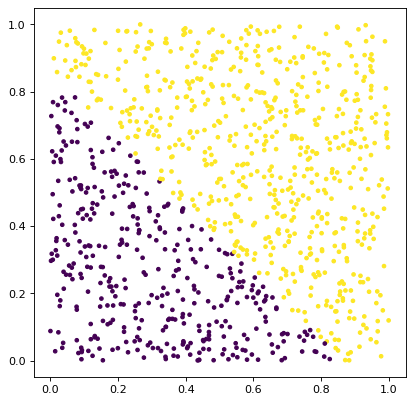

In [ ]:
X_lin, y_lin = linearly_separable_dataset(1000, seed=13)

plt.scatter(X_lin[:, 0], X_lin[:, 1], c=y_lin, s=10)

**Finally**, shall we test how the WiSARD fares against the dataset?

In [ ]:
@interact_manual(
    seed=fixed(1),
    tuple_size=(2, 64),
    resolution=(8, 256),
    noise=(0.0, 0.5, 0.01))
def test_linear_classifier(seed, tuple_size=16, resolution=64, noise=0.0):
    X_lin, y_lin = linearly_separable_dataset(1000, seed=seed)

    classifier_testbed(
        X_lin,
        y_lin,
        tuple_size=tuple_size,
        noise=noise,
        encoders={
            'Simple encoding': ThermometerEncoder(0.0, 1.0, resolution),
            'Circular encoding': CircularThermometerEncoder(0.0, 1.0, resolution, wrap=True)
        },
        seed=seed,
        bleaching=True,
        layout='row',
        subplot_size=(8, 8),
        mental_images=False
    )

interactive(children=(IntSlider(value=16, description='tuple_size', max=64, min=2), IntSlider(value=64, descri…

### A "wiggly" case-study

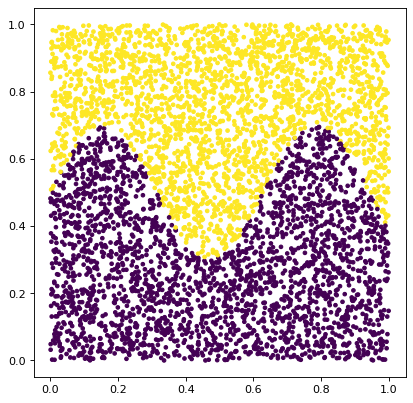

In [ ]:
X_wig, y_wig = sinusoidal_dataset(5000, seed=1)

plt.scatter(X_wig[:, 0], X_wig[:, 1], c=y_wig, s=10)

In [ ]:
@interact_manual(
    seed=fixed(1),
    tuple_size=(2, 64),
    resolution=(8, 256),
    noise=(0.0, 0.5, 0.01))
def test_wiggly_classifier(seed, tuple_size=16, resolution=64, noise=0.0):
    X_wig, y_wig = sinusoidal_dataset(1000, seed=seed)

    classifier_testbed(
        X_wig,
        y_wig,
        tuple_size=tuple_size,
        noise=noise,
        encoders={
            'Simple encoding': ThermometerEncoder(0.0, 1.0, resolution),
            'Circular encoding': CircularThermometerEncoder(0.0, 1.0, resolution, wrap=True)
        },
        seed=seed,
        layout='row',
        subplot_size=(5, 5),
        mental_images=False
    )

interactive(children=(IntSlider(value=16, description='tuple_size', max=64, min=2), IntSlider(value=64, descri…

### 3.3. A radially separable case-study

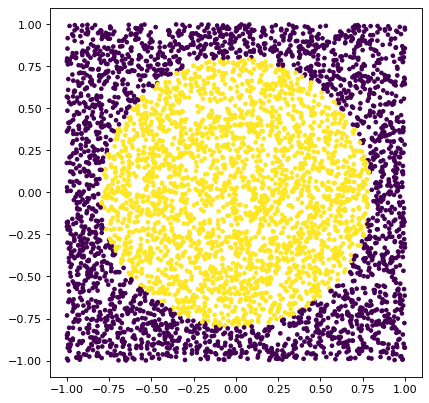

In [ ]:
X_r, y_r = radially_separable_dataset(5000, radius=np.sqrt(2/np.pi), seed=17)

plt.scatter(X_r[:, 0], X_r[:, 1], c=y_r, s=10)

In [ ]:
@interact_manual(
    seed=fixed(1),
    tuple_size=(2, 64),
    resolution=(8, 256),
    noise=(0.0, 0.5, 0.01))
def test_nonlinear_classifier(seed, tuple_size=16, resolution=64, noise=0.0):
    X_r, y_r = radially_separable_dataset(1000, radius=np.sqrt(2/np.pi), seed=seed)

    classifier_testbed(
        X_r,
        y_r,
        tuple_size=tuple_size,
        noise=noise,
        encoders={
            'Simple encoding': ThermometerEncoder(-1.0, 1.0, resolution),
            'Circular encoding': CircularThermometerEncoder(-1.0, 1.0, resolution, wrap=True)
        },
        seed=seed,
        layout='row',
        mental_images=False
    )

interactive(children=(IntSlider(value=16, description='tuple_size', max=64, min=2), IntSlider(value=64, descri…

### 3.4. A donut case study


In [ ]:
from numpy.random import default_rng

def donut_dataset(N, r1=0.2, r2=0.5, seed=None):
    rng = default_rng(seed)
    X = rng.uniform(low=-1.0, high=1.0, size=(N, 2))

    y = np.where((X[:, 0]**2 + X[:, 1]**2 <= r2**2) &
             (X[:, 0]**2 + X[:, 1]**2 > r1**2), 1, -1)

    return X, y

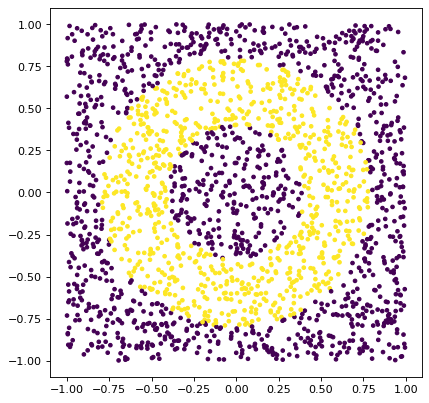

In [ ]:
X_r, y_r = donut_dataset(2000, r1=np.sqrt(0.5/np.pi), r2=np.sqrt(2/np.pi), seed=17)

plt.scatter(X_r[:, 0], X_r[:, 1], c=y_r, s=10)

- Nota: Demora cerca de 1 minuto passando 2000 termos

In [ ]:
@interact_manual(
    seed=fixed(1),
    tuple_size=(2, 64),
    resolution=(8, 256),
    noise=(0.0, 0.5, 0.01))
def test_nonlinear_classifier(seed, tuple_size=16, resolution=64, noise=0.0):
    X_r, y_r = donut_dataset(1000, r1=np.sqrt(0.5/np.pi), r2=np.sqrt(2/np.pi), seed=seed)

    classifier_testbed(
        X_r,
        y_r,
        tuple_size=tuple_size,
        noise=noise,
        encoders={
            'Simple encoding': ThermometerEncoder(-1.0, 1.0, resolution),
            'Circular encoding': CircularThermometerEncoder(-1.0, 1.0, resolution, wrap=True)
        },
        seed=seed,
        layout='row',
        mental_images=False
    )

interactive(children=(IntSlider(value=16, description='tuple_size', max=64, min=2), IntSlider(value=64, descri…